In [ ]:
!pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 11.7 MB/s  0:00:00


In [ ]:
import os, warnings, random, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore"); warnings.simplefilter("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from arch import arch_model
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning, InterpolationWarning
for _w in (ConvergenceWarning, EstimationWarning, InterpolationWarning): warnings.filterwarnings("ignore", category=_w)
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
DATA_PATH = os.environ.get("DATA_PATH", "DEXSLUS.csv")
OUT_DIR = os.environ.get("OUT_DIR", "results_2021_2025"); os.makedirs(OUT_DIR, exist_ok=True)
START, END = "2021-01-01", "2025-12-31"
TRAIN_END, VAL_END = pd.Timestamp("2023-12-31"), pd.Timestamp("2024-12-31")   # train | validation | test
STEP = 21                       # re-estimate every 21 trading days (about monthly)
WINDOW_CANDIDATES = [250, 500, None]   # rolling window length W (None = expanding); chosen on validation
LOOKBACK = 10                   # sequence length for LSTM / GRU
N_SEEDS = int(os.environ.get("N_SEEDS", 3))   # TensorFlow seeds averaged per network (use 5 for the final run)
EPOCHS, PATIENCE, BATCH, CLIP, SEED = 150, 10, 32, 5.0, 42
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
def savefig(n): plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{n}.png", bbox_inches="tight"); plt.show(); plt.close()
T0 = time.time()
def tick(msg): print(f"[{(time.time()-T0)/60:5.1f} min] {msg}", flush=True)

In [ ]:
if not os.path.exists(DATA_PATH):
    from google.colab import files
    DATA_PATH = list(files.upload().keys())[0]
print("Using data file:", DATA_PATH)

Saving DEXSLUS (1).csv to DEXSLUS (1).csv
Using data file: DEXSLUS (1).csv


In [ ]:
raw = pd.read_csv(DATA_PATH, na_values=[".", ""])
raw = raw.iloc[:, :2]; raw.columns = ["date", "usd_lkr"]
raw["date"] = pd.to_datetime(raw["date"]); raw["usd_lkr"] = pd.to_numeric(raw["usd_lkr"], errors="coerce")
raw = raw.sort_values("date").set_index("date").loc[START:END]
print("rows:", len(raw), "| blank (US holidays):", raw.usd_lkr.isna().sum(), "| duplicated dates:", raw.index.duplicated().sum())
s = raw["usd_lkr"].dropna().astype(float)
assert s.index.is_monotonic_increasing and not s.index.duplicated().any() and (s > 0).all()
lp = np.log(s); ret = (lp.diff().dropna() * 100).rename("ret")
print("clean observations:", len(s), s.index.min().date(), "->", s.index.max().date(), "| min/max:", s.min(), s.max())
print("daily log returns (%):\n", ret.describe().round(4)); print("zero-return days:", int((ret == 0).sum()), f"({(ret==0).mean()*100:.1f}%)")

rows: 1303 | blank (US holidays): 54 | duplicated dates: 0
clean observations: 1249 2021-01-04 -> 2025-12-31 | min/max: 184.97 365.43
daily log returns (%):
 count    1248.0000
mean        0.0412
std         0.7251
min        -4.5810
25%        -0.1068
50%         0.0000
75%         0.1302
max        11.4729
Name: ret, dtype: float64
zero-return days: 202 (16.2%)


In [ ]:
yr = ret.groupby(ret.index.year).agg(n="count", mean="mean", std="std", max_abs=lambda x: x.abs().max())
yr["zero_share_%"] = ret.groupby(ret.index.year).apply(lambda x: (x == 0).mean() * 100)
yr["acf_lag1"] = ret.groupby(ret.index.year).apply(lambda x: x.autocorr(1))
print("\nBy calendar year (regime summary):\n", yr.round(3).to_string()); yr.round(4).to_csv(f"{OUT_DIR}/yearly_summary.csv")

# chronological blocks of returns
train_ret = ret.loc[:TRAIN_END]; val_ret = ret.loc[TRAIN_END:VAL_END].iloc[1:]; test_ret = ret.loc[VAL_END:].iloc[1:]
print(f"\ntrain {len(train_ret)} ({train_ret.index[0].date()}..{train_ret.index[-1].date()}) | val {len(val_ret)} ({val_ret.index[0].date()}..{val_ret.index[-1].date()}) | test {len(test_ret)} ({test_ret.index[0].date()}..{test_ret.index[-1].date()})")


By calendar year (regime summary):
         n   mean    std  max_abs  zero_share_%  acf_lag1
date                                                    
2021  248  0.037  0.486    3.539        24.194     0.057
2022  250  0.233  1.301   11.473        28.400    -0.042
2023  249 -0.046  0.752    4.581        11.647     0.199
2024  251 -0.040  0.243    0.908         5.179     0.193
2025  250  0.022  0.176    1.231        11.600    -0.142

train 747 (2021-01-05..2023-12-29) | val 250 (2024-01-03..2024-12-31) | test 250 (2025-01-02..2025-12-31)


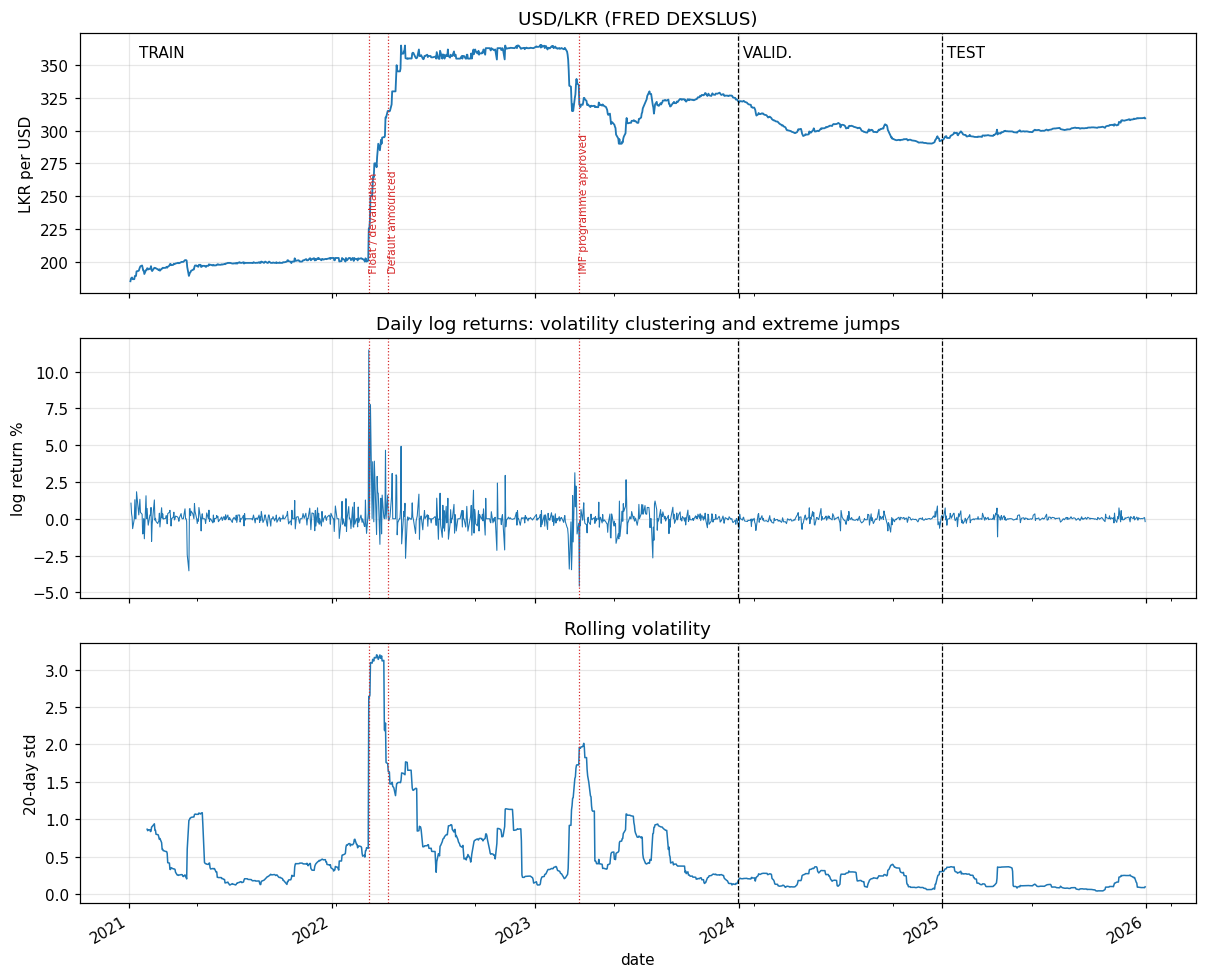

In [ ]:
EV = [("2022-03-08", "Float / devaluation"), ("2022-04-12", "Default announced"), ("2023-03-20", "IMF programme approved")]
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
s.plot(ax=ax[0], lw=1.2); ax[0].set_ylabel("LKR per USD"); ax[0].set_title("USD/LKR (FRED DEXSLUS)")
ret.plot(ax=ax[1], lw=.7); ax[1].set_ylabel("log return %"); ax[1].set_title("Daily log returns: volatility clustering and extreme jumps")
ret.rolling(20).std().plot(ax=ax[2], lw=1); ax[2].set_ylabel("20-day std"); ax[2].set_title("Rolling volatility")
for a in ax:
    for d_, c in [(TRAIN_END, "k"), (VAL_END, "k")]: a.axvline(d_, color=c, ls="--", lw=.8)
    for d_, _ in EV: a.axvline(pd.Timestamp(d_), color="tab:red", ls=":", lw=.8)
ymax = s.max()
ax[0].text(s.index[10], ymax, "TRAIN", va="top"); ax[0].text(TRAIN_END, ymax, " VALID.", va="top"); ax[0].text(VAL_END, ymax, " TEST", va="top")
for d_, t_ in EV: ax[0].text(pd.Timestamp(d_), s.min() + 4, " " + t_, rotation=90, fontsize=7, color="tab:red", va="bottom")
savefig("01_eda_price_returns_vol")

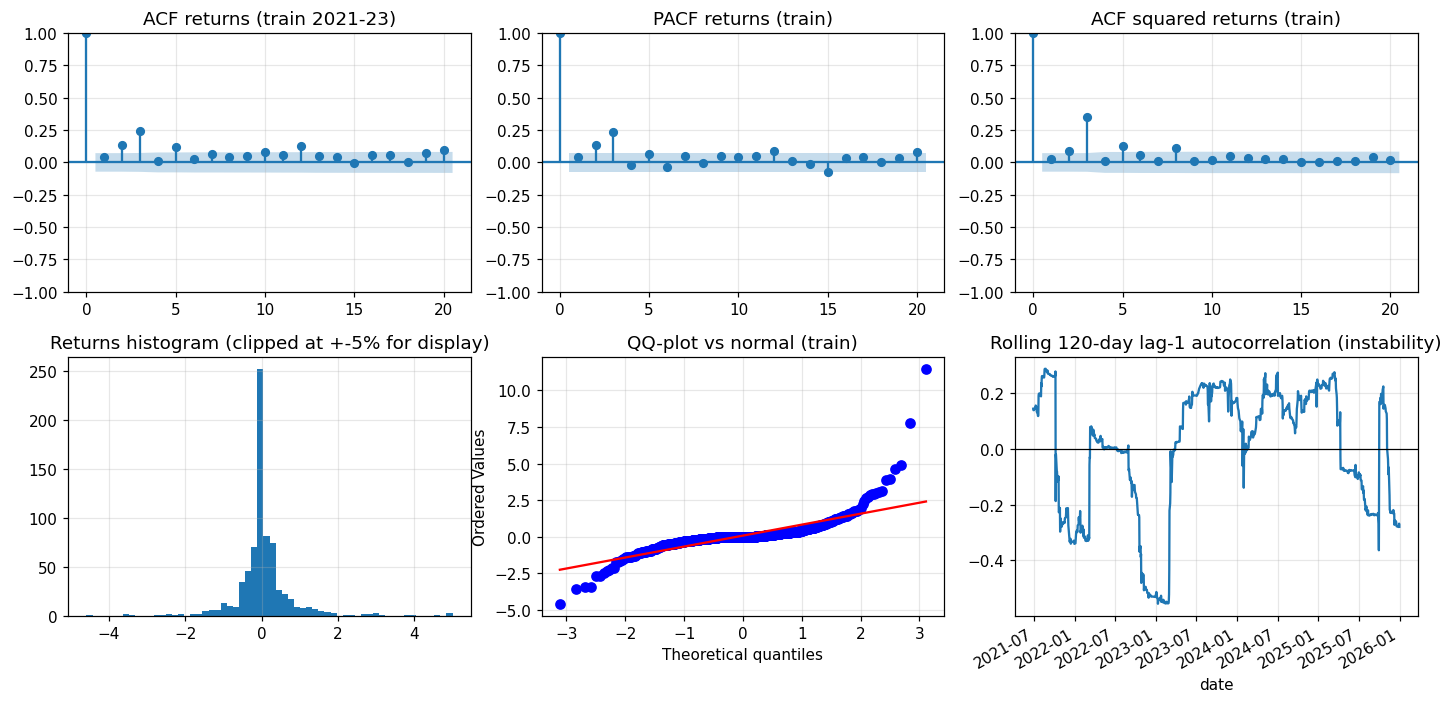

In [ ]:
post = ret.loc["2023-01-01":TRAIN_END]            # managed-float part of the training block
fig, ax = plt.subplots(2, 3, figsize=(13, 6.5))
plot_acf(train_ret, lags=20, ax=ax[0, 0], title="ACF returns (train 2021-23)"); plot_pacf(train_ret, lags=20, ax=ax[0, 1], title="PACF returns (train)")
plot_acf(train_ret ** 2, lags=20, ax=ax[0, 2], title="ACF squared returns (train)")
ax[1, 0].hist(train_ret.clip(-5, 5), bins=60); ax[1, 0].set_title("Returns histogram (clipped at +-5% for display)")
stats.probplot(train_ret, dist="norm", plot=ax[1, 1]); ax[1, 1].set_title("QQ-plot vs normal (train)")
ret.rolling(120).corr(ret.shift(1)).plot(ax=ax[1, 2]); ax[1, 2].axhline(0, c="k", lw=.8); ax[1, 2].set_title("Rolling 120-day lag-1 autocorrelation (instability)")
savefig("02_acf_distribution_instability")

In [ ]:
a1, k1 = adfuller(lp.loc[:TRAIN_END], autolag="AIC"), kpss(lp.loc[:TRAIN_END], regression="c", nlags="auto")
a2, k2 = adfuller(train_ret, autolag="AIC"), kpss(train_ret, regression="c", nlags="auto")
tests = pd.DataFrame([["log price", a1[0], a1[1], k1[0], k1[1]], ["log return", a2[0], a2[1], k2[0], k2[1]]],
                     columns=["series (train)", "ADF stat", "ADF p", "KPSS stat", "KPSS p"]).round(4); print(tests.to_string(index=False))
print("Ljung-Box(10) returns p        =", round(acorr_ljungbox(train_ret, lags=[10]).lb_pvalue.iloc[0], 4))
print("Ljung-Box(10) squared returns p =", round(acorr_ljungbox(train_ret ** 2, lags=[10]).lb_pvalue.iloc[0], 4))
print("ARCH-LM(10) p                   =", round(het_arch(train_ret, nlags=10)[1], 4))
jb = stats.jarque_bera(train_ret); print(f"Jarque-Bera p = {jb.pvalue:.3g} | skew {stats.skew(train_ret):.2f} | excess kurtosis {stats.kurtosis(train_ret):.2f}")
print("mean daily return (train) %:", round(train_ret.mean(), 4), "| t-stat vs 0:", round(stats.ttest_1samp(train_ret, 0).statistic, 2))
try:
    from statsmodels.tsa.stattools import zivot_andrews
    za = zivot_andrews(lp.loc[:TRAIN_END], regression="c", autolag="AIC")
    print(f"Zivot-Andrews (one structural break in log price): stat {za[0]:.2f}, p {za[1]:.3f}, break at {lp.loc[:TRAIN_END].index[za[4]].date()}")
except Exception as e: print("Zivot-Andrews skipped:", type(e).__name__)
print("\nEquality of variance across regimes (Levene): 2024 vs 2025 p =", round(stats.levene(ret["2024"], ret["2025"]).pvalue, 4))
tests.to_csv(f"{OUT_DIR}/stationarity_tests.csv", index=False)


series (train)  ADF stat  ADF p  KPSS stat  KPSS p
     log price   -1.2635 0.6457     3.1389    0.01
    log return  -11.1054 0.0000     0.3133    0.10
Ljung-Box(10) returns p        = 0.0
Ljung-Box(10) squared returns p = 0.0
ARCH-LM(10) p                   = 0.0
Jarque-Bera p = 0 | skew 3.67 | excess kurtosis 41.81
mean daily return (train) %: 0.075 | t-stat vs 0: 2.23
Zivot-Andrews (one structural break in log price): stat -10.44, p 0.000, break at 2022-03-07

Equality of variance across regimes (Levene): 2024 vs 2025 p = 0.0


In [ ]:
def make_features(ret, lp):
    f = pd.DataFrame(index=ret.index)
    for k in range(1, 6): f[f"r_lag{k}"] = ret.shift(k)
    r1 = ret.shift(1); f["abs_lag1"] = r1.abs()
    for w in (5, 10, 20): f[f"vol{w}"] = r1.rolling(w).std()
    for w in (5, 10, 20): f[f"mom{w}"] = r1.rolling(w).sum()
    lp1 = lp.reindex(ret.index).shift(1)
    for w in (10, 20): f[f"dev_ma{w}"] = (lp1 - lp1.rolling(w).mean()) * 100
    return f
F = make_features(ret, lp).dropna(); idx = F.index; n = len(idx)
tr_m = np.asarray(idx <= TRAIN_END); va_m = np.asarray((idx > TRAIN_END) & (idx <= VAL_END)); te_m = np.asarray(idx > VAL_END)
print("model rows train/val/test:", tr_m.sum(), va_m.sum(), te_m.sum(), "| features:", list(F.columns))
FV = F.values.astype(float)
Y1 = ret.reindex(idx).values.astype(float)
LPV = lp.reindex(idx).values.astype(float); LPP = lp.shift(1).reindex(idx).values.astype(float)
pos_ret = ret.index.get_indexer(idx); rv = ret.values.astype(float)
SEQ = np.stack([np.stack([rv[p - LOOKBACK:p] for p in pos_ret]), np.abs(np.stack([rv[p - LOOKBACK:p] for p in pos_ret]))], -1)   # (n, L, 2)
pred = pd.DataFrame({"y": Y1, "P_prev": s.shift(1).reindex(idx).values, "P_act": s.reindex(idx).values}, index=idx)

model rows train/val/test: 727 251 250 | features: ['r_lag1', 'r_lag2', 'r_lag3', 'r_lag4', 'r_lag5', 'abs_lag1', 'vol5', 'vol10', 'vol20', 'mom5', 'mom10', 'mom20', 'dev_ma10', 'dev_ma20']


In [ ]:
def metrics(df, col):
    rh = df[col]; ph = df.P_prev * np.exp(rh / 100); e = df.P_act - ph; nz = (df.y != 0) & (rh != 0)
    return dict(MAE=e.abs().mean(), RMSE=np.sqrt((e ** 2).mean()), MAPE_pct=(e.abs() / df.P_act).mean() * 100,
                DirAcc_pct=(np.sign(df.y[nz]) == np.sign(rh[nz])).mean() * 100 if nz.sum() > 10 else np.nan)
def rmse_arr(arr, mask):
    d = pred[mask]; return float(np.sqrt(((d.P_act - d.P_prev * np.exp(arr[mask] / 100)) ** 2).mean()))
def dm_test(e1, e2, lag=2):          # Diebold-Mariano, squared price-error loss, Newey-West variance; stat > 0 => model 2 better
    d = (np.asarray(e1) ** 2 - np.asarray(e2) ** 2); m = len(d); dm = d - d.mean(); var = (dm @ dm) / m
    for k in range(1, lag + 1): var += 2 * (1 - k / (lag + 1)) * (dm[k:] @ dm[:-k]) / m
    st = d.mean() / np.sqrt(var / m); return st, 2 * (1 - stats.norm.cdf(abs(st)))

In [ ]:
def walk_forward(fn, mask, window, gap=0, step=STEP):
    """Refit every `step` rows on the latest `window` rows that end `gap` rows before the chunk, then forecast the chunk."""
    ps = np.where(mask)[0]; outs = []
    for s0 in range(0, len(ps), step):
        ch = ps[s0:s0 + step]; tr = np.arange(0, ch[0] - gap)
        if window: tr = tr[-window:]
        outs.append(np.asarray(fn(tr, ch), float))
    return np.concatenate(outs, axis=-1)
def run_model(fn, window, masks=None, gap=0):
    masks = masks or (va_m, te_m); res = None
    for mk in masks:
        o = walk_forward(fn, mk, window, gap)
        if res is None: res = np.full(o.shape[:-1] + (n,), np.nan)
        res[..., np.where(mk)[0]] = o
    return res

In [ ]:
FAILS = {"n": 0}
def drift_fn(tr, ch): return np.full(len(ch), Y1[tr].mean())
def arima_fn(order):
    def f(tr, ch):
        try:
            yw = Y1[tr]; res = ARIMA(yw, order=order, trend="c").fit()
            return res.apply(np.r_[yw, Y1[ch]], refit=False).fittedvalues[-len(ch):]
        except Exception: FAILS["n"] += 1; return np.zeros(len(ch))
    return f
def ets_fn(tr, ch):      # ETS(A,Ad,N): damped additive trend on log price, parameters estimated in the window, recursion run forward without look-ahead
    try:
        fit = ExponentialSmoothing(LPV[tr], trend="add", damped_trend=True, initialization_method="estimated").fit()
        a, bt, phi = fit.params["smoothing_level"], fit.params["smoothing_trend"], fit.params["damping_trend"]
        l, b, out = LPV[tr[0]], 0.0, []
        for t in np.r_[tr, ch]:
            out.append(l + phi * b)                                   # forecast for t uses only information up to t-1
            l_new = a * LPV[t] + (1 - a) * (l + phi * b); b = bt * (l_new - l) + (1 - bt) * phi * b; l = l_new
        return (np.array(out[-len(ch):]) - LPP[ch]) * 100
    except Exception: FAILS["n"] += 1; return np.zeros(len(ch))
G_SIG, G_NU, G_MU = np.full(n, np.nan), np.full(n, np.nan), np.full(n, np.nan)
def garch_fn(tr, ch):
    try:
        yw = Y1[tr]; am = arch_model(yw, mean="AR", lags=1, vol="GARCH", p=1, q=1, dist="t", rescale=False)
        r = am.fit(disp="off", options={"maxiter": 500}); full = np.r_[yw, Y1[ch]]
        g = arch_model(full, mean="AR", lags=1, vol="GARCH", p=1, q=1, dist="t", rescale=False).fix(r.params)
        mu = (full - np.asarray(g.resid))[-len(ch):]; mu = np.where(np.isfinite(mu), mu, 0.0)
        G_SIG[ch] = np.asarray(g.conditional_volatility)[-len(ch):]; G_NU[ch] = r.params["nu"]; G_MU[ch] = mu
        return mu
    except Exception: FAILS["n"] += 1; return np.zeros(len(ch))

 p  q    AIC    BIC
 3  0 1894.6 1917.5
 0  3 1900.5 1923.4
 3  1 1896.3 1923.9
 3  2 1893.8 1925.9
 2  3 1897.0 1929.1
ARIMA(3,1,0) selected by BIC on the training block
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0692      0.062      1.123      0.261      -0.052       0.190
ar.L1          0.0024      0.030      0.080      0.936      -0.057       0.062
ar.L2          0.1220      0.024      5.187      0.000       0.076       0.168
ar.L3          0.2418      0.014     16.877      0.000       0.214       0.270
sigma2         0.7820      0.010     74.739      0.000       0.761       0.803
ARIMA residual Ljung-Box(10) p = 0.834 | squared residuals p = 0.0067


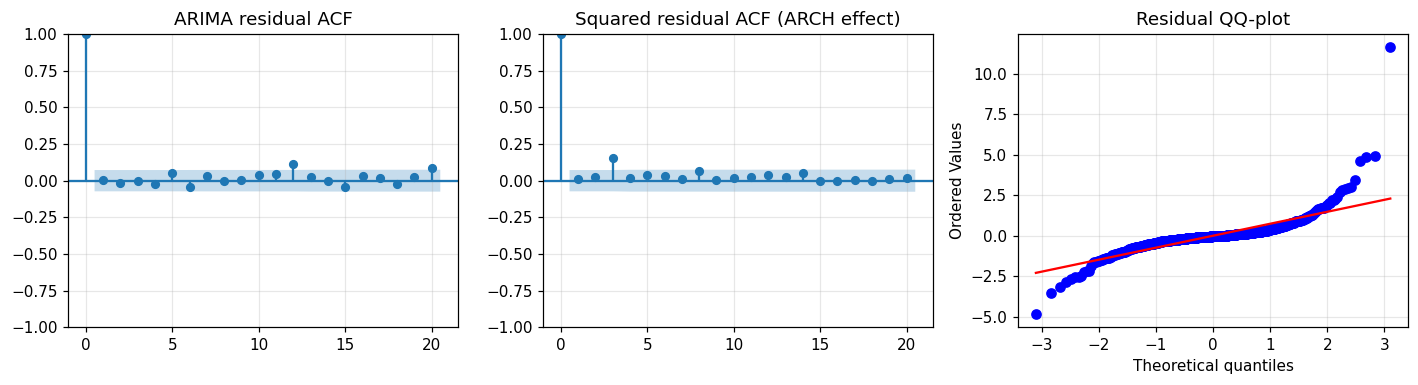

AR(1)-GARCH(1,1)-t fitted on the training block:
 Const       0.0144
y[1]       -0.1669
omega       0.0175
alpha[1]    0.3025
beta[1]     0.6975
nu          2.8468
persistence alpha+beta = 1.0
GARCH std-resid Ljung-Box(10) p: 0.4863 | squared: 1.0


In [ ]:
y_tr = Y1[tr_m]; grid = []
for p in range(4):
    for q in range(4):
        try: r_ = ARIMA(y_tr, order=(p, 0, q), trend="c").fit(); grid.append((p, q, r_.aic, r_.bic))
        except Exception: pass
grid = pd.DataFrame(grid, columns=["p", "q", "AIC", "BIC"]).sort_values("BIC"); print(grid.head(5).round(1).to_string(index=False))
P_B, Q_B = int(grid.iloc[0].p), int(grid.iloc[0].q); print(f"ARIMA({P_B},1,{Q_B}) selected by BIC on the training block")
arima_train = ARIMA(y_tr, order=(P_B, 0, Q_B), trend="c").fit(); print(arima_train.summary().tables[1])
res_a = pd.Series(arima_train.resid, index=idx[tr_m])
print("ARIMA residual Ljung-Box(10) p =", round(acorr_ljungbox(res_a, lags=[10]).lb_pvalue.iloc[0], 4), "| squared residuals p =", round(acorr_ljungbox(res_a ** 2, lags=[10]).lb_pvalue.iloc[0], 4))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
plot_acf(res_a, lags=20, ax=ax[0], title="ARIMA residual ACF"); plot_acf(res_a ** 2, lags=20, ax=ax[1], title="Squared residual ACF (ARCH effect)")
stats.probplot(res_a, dist="norm", plot=ax[2]); ax[2].set_title("Residual QQ-plot"); savefig("03_arima_diagnostics")
g0 = arch_model(y_tr, mean="AR", lags=1, vol="GARCH", p=1, q=1, dist="t", rescale=False).fit(disp="off")
print("AR(1)-GARCH(1,1)-t fitted on the training block:\n", g0.params.round(4).to_string()); print("persistence alpha+beta =", round(g0.params["alpha[1]"] + g0.params["beta[1]"], 3))
z = pd.Series(np.asarray(g0.std_resid), index=idx[tr_m]).dropna()
print("GARCH std-resid Ljung-Box(10) p:", round(acorr_ljungbox(z, lags=[10]).lb_pvalue.iloc[0], 4), "| squared:", round(acorr_ljungbox(z ** 2, lags=[10]).lb_pvalue.iloc[0], 4))

In [ ]:
def ml_fn(make_model, Yt=None):
    Yt = Y1 if Yt is None else Yt
    def f(tr, ch):
        X = FV[tr]; mu, sd = X.mean(0), X.std(0) + 1e-9
        Xtr, Xte = np.clip((X - mu) / sd, -CLIP, CLIP), np.clip((FV[ch] - mu) / sd, -CLIP, CLIP)
        yt = Yt[tr]; sdy = yt.std() + 1e-9; lo, hi = np.percentile(yt, [1, 99]); yt = np.clip(yt, lo, hi) / sdy
        m = make_model(); m.fit(Xtr, yt); return m.predict(Xte) * sdy
    return f
def make(name, **kw):
    if name == "Ridge": return lambda: Ridge(alpha=kw.get("alpha", 100))
    if name == "RF":    return lambda: RandomForestRegressor(200, min_samples_leaf=kw.get("min_samples_leaf", 10), max_features=kw.get("max_features", .5), random_state=SEED, n_jobs=-1)
    if name == "SVR":   return lambda: SVR(C=kw.get("C", .3), gamma=kw.get("gamma", .03), epsilon=.1)
    if name == "XGB":   return lambda: XGBRegressor(n_estimators=kw.get("n_estimators", 100), max_depth=kw.get("max_depth", 2), learning_rate=.03,
                                                      subsample=.8, colsample_bytree=.8, random_state=SEED, n_jobs=2, verbosity=0)
FAST = ["Ridge", "RF", "SVR", "XGB"]
naive_val = rmse_arr(np.zeros(n), va_m)

In [ ]:
rows = []
for W in WINDOW_CANDIDATES:
    r_ = {f"{m}": rmse_arr(run_model(ml_fn(make(m)), W, masks=(va_m,)), va_m) / naive_val for m in FAST}
    r_.update(ARIMA11=rmse_arr(run_model(arima_fn((1, 0, 1)), W, masks=(va_m,)), va_m) / naive_val)
    rows.append({"window": "expanding" if W is None else W, **r_, "mean_ratio": np.mean(list(r_.values()))})
wtab = pd.DataFrame(rows); print("Validation RMSE / naive by window length W:\n", wtab.round(3).to_string(index=False))
WIN = WINDOW_CANDIDATES[int(wtab.mean_ratio.values.argmin())]; print("selected window W =", WIN); wtab.to_csv(f"{OUT_DIR}/window_selection_validation.csv", index=False)
tick("window chosen")

Validation RMSE / naive by window length W:
    window  Ridge    RF   SVR   XGB  ARIMA11  mean_ratio
      250  0.989 1.030 1.002 1.006    0.974       1.000
      500  0.968 1.014 0.998 1.015    0.977       0.994
expanding  0.995 1.012 1.018 1.064    0.990       1.016
selected window W = 500
[  5.4 min] window chosen


In [ ]:
GRIDS = {"Ridge": [dict(alpha=a) for a in (10, 100, 1000, 5000)],
         "RF": [dict(min_samples_leaf=l, max_features=f) for l in (5, 10, 20) for f in (.33, .66)],
         "SVR": [dict(C=c, gamma=g) for c in (.1, .3, 1) for g in (.01, .03, .1)],
         "XGB": [dict(max_depth=d, n_estimators=k) for d in (2, 3) for k in (50, 100, 200)]}
BEST, tune_rows = {}, []
for m, gl in GRIDS.items():
    sc = []
    for kw in gl:
        v = rmse_arr(run_model(ml_fn(make(m, **kw)), WIN, masks=(va_m,)), va_m) / naive_val; sc.append(v); tune_rows.append({"model": m, **kw, "val_RMSE_vs_naive": v})
    BEST[m] = gl[int(np.argmin(sc))]; print(f"{m:6s} best on validation: {BEST[m]}  (RMSE/naive {min(sc):.3f})")
pd.DataFrame(tune_rows).to_csv(f"{OUT_DIR}/tuning_grid_validation.csv", index=False); tick("fast ML tuned")

Ridge  best on validation: {'alpha': 100}  (RMSE/naive 0.968)
RF     best on validation: {'min_samples_leaf': 20, 'max_features': 0.33}  (RMSE/naive 1.004)
SVR    best on validation: {'C': 0.1, 'gamma': 0.01}  (RMSE/naive 0.985)
XGB    best on validation: {'max_depth': 2, 'n_estimators': 50}  (RMSE/naive 1.014)
[  7.1 min] fast ML tuned


In [ ]:
HIST = {}
def make_inputs(kind, tr, Yt):
    sdy = Yt[tr].std() + 1e-9
    if kind == "mlp":
        mu, sd = FV[tr].mean(0), FV[tr].std(0) + 1e-9
        return (lambda rows: np.clip((FV[rows] - mu) / sd, -CLIP, CLIP).astype("float32")), sdy
    return (lambda rows: np.clip(SEQ[rows] / sdy, -CLIP, CLIP).astype("float32")), sdy
def build_nn(kind, shape, units, l2):
    reg = keras.regularizers.l2(l2)
    if kind == "mlp":  return keras.Sequential([layers.Input(shape), layers.Dense(units, activation="relu", kernel_regularizer=reg), layers.Dropout(.2),
                                                layers.Dense(max(units // 2, 4), activation="relu"), layers.Dense(1)])
    core = layers.LSTM(units) if kind == "lstm" else layers.GRU(units)
    return keras.Sequential([layers.Input(shape), core, layers.Dropout(.2), layers.Dense(8, activation="relu"), layers.Dense(1)])
def nn_train(kind, tr, seed, units=16, l2=1e-3, Yt=None):
    Yt = Y1 if Yt is None else Yt
    inp, sdy = make_inputs(kind, tr, Yt); n_in = int(len(tr) * .8); a, b = tr[:n_in], tr[n_in:]
    ys = lambda rows: np.clip(Yt[rows] / sdy, -CLIP, CLIP).astype("float32")
    keras.utils.set_random_seed(seed); m = build_nn(kind, inp(a[:1]).shape[1:], units, l2)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss=keras.losses.Huber(1.0))
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    h = m.fit(inp(a), ys(a), validation_data=(inp(b), ys(b)), epochs=EPOCHS, batch_size=BATCH, shuffle=True, callbacks=[es], verbose=0)
    return m, inp, sdy, h.history
def nn_fn(kind, seeds, units=16, l2=1e-3, Yt=None):
    def f(tr, ch):
        out = []
        for k in seeds:
            m, inp, sdy, h = nn_train(kind, tr, SEED + k, units, l2, Yt); out.append(m.predict(inp(ch), verbose=0).ravel() * sdy)
            if k == seeds[0]: HIST[kind] = h
            keras.backend.clear_session()
        return np.array(out)
    return f

In [ ]:
mlp_rows = []
for units in (8, 16):
    for l2 in (1e-3, 1e-2):
        v = rmse_arr(run_model(nn_fn("mlp", [0], units, l2), WIN, masks=(va_m,))[0], va_m) / naive_val; mlp_rows.append({"units": units, "l2": l2, "val_RMSE_vs_naive": v})
mlp_t = pd.DataFrame(mlp_rows); print("MLP tuning (validation):\n", mlp_t.round(3).to_string(index=False)); b_ = mlp_t.loc[mlp_t.val_RMSE_vs_naive.idxmin()]
MLP_UNITS, MLP_L2 = int(b_.units), float(b_.l2); print("selected MLP:", MLP_UNITS, "units, l2 =", MLP_L2); mlp_t.to_csv(f"{OUT_DIR}/tuning_mlp_validation.csv", index=False); tick("MLP tuned")

MLP tuning (validation):
  units    l2  val_RMSE_vs_naive
     8 0.001              0.994
     8 0.010              0.992
    16 0.001              0.992
    16 0.010              0.992
selected MLP: 8 units, l2 = 0.01
[ 17.7 min] MLP tuned


In [ ]:
SEEDS = list(range(N_SEEDS)); seed_preds = {}
def put(name, arr): pred[name] = arr
put("Naive", np.where(va_m | te_m, 0.0, np.nan))
put("Drift", run_model(drift_fn, WIN))
put("ARIMA", run_model(arima_fn((P_B, 0, Q_B)), WIN)); put("ARIMA111", run_model(arima_fn((1, 0, 1)), WIN))
put("ETS", run_model(ets_fn, WIN)); put("ARGARCH", run_model(garch_fn, WIN)); tick(f"traditional done (fit failures: {FAILS['n']})")
for m in FAST: put(m, run_model(ml_fn(make(m, **BEST[m])), WIN))
tick("sklearn / XGBoost done")
for kind in ["mlp", "lstm", "gru"]:
    sp = run_model(nn_fn(kind, SEEDS, MLP_UNITS if kind == "mlp" else 16, MLP_L2 if kind == "mlp" else 1e-3), WIN); seed_preds[kind] = sp; put(kind.upper(), sp.mean(0)); tick(f"{kind.upper()} done")
MLM = ["Ridge", "RF", "SVR", "XGB", "MLP", "LSTM", "GRU"]; TRM = ["ARIMA", "ARIMA111", "ETS", "ARGARCH"]
put("Ens_ML", pred[MLM].mean(1)); put("Ens_All", pred[TRM + MLM].mean(1))
valr = {m: rmse_arr(pred[m].values, va_m) for m in TRM + MLM}; top3 = sorted(valr, key=valr.get)[:3]; print("Top-3 models on validation:", top3)
put("Ens_Top3_Val", pred[top3].mean(1))
FAMILY = {"Naive": "Baseline", "Drift": "Baseline", **{m: "Traditional" for m in TRM}, **{m: "Machine learning" for m in MLM}, "Ens_ML": "Ensemble", "Ens_All": "Ensemble", "Ens_Top3_Val": "Ensemble"}
MODELS = list(FAMILY); pred.to_csv(f"{OUT_DIR}/predictions_return_pct.csv")

[ 24.6 min] traditional done (fit failures: 0)
[ 24.8 min] sklearn / XGBoost done
[ 45.6 min] MLP done
[ 55.4 min] LSTM done
[ 66.3 min] GRU done
Top-3 models on validation: ['Ridge', 'ARIMA111', 'SVR']


In [ ]:
vol10 = pd.Series(F["vol10"].values, index=idx); thr = np.percentile(vol10[va_m | te_m], 75)
SETS = {"Validation 2024": va_m, "Test 2025": te_m, "Test, calm days (vol10<=P75)": te_m & (vol10.values <= thr), "Test, volatile days (vol10>P75)": te_m & (vol10.values > thr)}
rows = []
for sn, mk in SETS.items():
    d = pred[mk]
    for m in MODELS: rows.append({"set": sn, "model": m, "family": FAMILY[m], "n": len(d), **metrics(d, m)})
res = pd.DataFrame(rows); base = res[res.model == "Naive"].set_index("set").RMSE; res["RMSE_vs_naive"] = res.apply(lambda r: r.RMSE / base[r.set], axis=1)
res.to_csv(f"{OUT_DIR}/metrics.csv", index=False)
for sn in SETS: print(f"\n== {sn} (n={res[res.set==sn].n.iloc[0]}) ==\n", res[res.set == sn].drop(columns=["set", "n"]).round(4).to_string(index=False))
print("\nvolatility threshold (P75 of 10-day vol over validation+test):", round(thr, 4))


== Validation 2024 (n=251) ==
        model           family    MAE   RMSE  MAPE_pct  DirAcc_pct  RMSE_vs_naive
       Naive         Baseline 0.5131 0.7434    0.1696         NaN         1.0000
       Drift         Baseline 0.5652 0.7934    0.1864     44.9580         1.0672
       ARIMA      Traditional 0.5225 0.7523    0.1725     54.6218         1.0119
    ARIMA111      Traditional 0.4909 0.7262    0.1623     63.0252         0.9767
         ETS      Traditional 0.5111 0.7402    0.1690     53.3613         0.9956
     ARGARCH      Traditional 0.5189 0.7595    0.1715     51.6807         1.0216
       Ridge Machine learning 0.4830 0.7196    0.1598     64.2857         0.9680
          RF Machine learning 0.5216 0.7467    0.1723     53.7815         1.0044
         SVR Machine learning 0.4966 0.7321    0.1642     65.5462         0.9848
         XGB Machine learning 0.5258 0.7537    0.1736     48.3193         1.0137
         MLP Machine learning 0.4907 0.7355    0.1624     68.4874         0.9

In [ ]:
dm_rows = []; d = pred[te_m]; en = d.P_act - d.P_prev
for m in MODELS[1:]:
    st_, p_ = dm_test(en, d.P_act - d.P_prev * np.exp(d[m] / 100)); dm_rows.append(["Test 2025", "vs Naive", m, st_, p_])
bt_ = min(TRM, key=lambda m: metrics(d, m)["RMSE"]); bm_ = min(MLM, key=lambda m: metrics(d, m)["RMSE"])
st_, p_ = dm_test(d.P_act - d.P_prev * np.exp(d[bt_] / 100), d.P_act - d.P_prev * np.exp(d[bm_] / 100)); dm_rows.append(["Test 2025", f"best traditional ({bt_}) vs best ML ({bm_})", bm_, st_, p_])
dm = pd.DataFrame(dm_rows, columns=["set", "comparison", "model", "DM_stat (>0: model better)", "p_value"]).round(4); print("\nDiebold-Mariano tests:\n", dm.to_string(index=False)); dm.to_csv(f"{OUT_DIR}/dm_tests.csv", index=False)


Diebold-Mariano tests:
       set                               comparison        model  DM_stat (>0: model better)  p_value
Test 2025                                 vs Naive        Drift                     -1.9338   0.0531
Test 2025                                 vs Naive        ARIMA                     -1.5550   0.1199
Test 2025                                 vs Naive     ARIMA111                     -1.4590   0.1446
Test 2025                                 vs Naive          ETS                     -0.8816   0.3780
Test 2025                                 vs Naive      ARGARCH                     -2.2571   0.0240
Test 2025                                 vs Naive        Ridge                     -1.0027   0.3160
Test 2025                                 vs Naive           RF                     -2.0192   0.0435
Test 2025                                 vs Naive          SVR                     -2.1421   0.0322
Test 2025                                 vs Naive          XGB   

In [ ]:
rng = np.random.default_rng(SEED); bt = []
for m in ["ARIMA", "ARIMA111", "ARGARCH", "XGB", "MLP", "LSTM", "GRU", "Ens_ML"]:
    em = (d.P_act - d.P_prev * np.exp(d[m] / 100)).values; nn_ = len(em); ratios = []
    for _ in range(2000):
        starts = rng.integers(0, nn_ - 4, size=int(np.ceil(nn_ / 5))); ii = np.concatenate([np.arange(s0, s0 + 5) for s0 in starts])[:nn_]
        ratios.append(np.sqrt((em[ii] ** 2).mean()) / np.sqrt((en.values[ii] ** 2).mean()))
    bt.append([m, np.sqrt((em ** 2).mean()) / np.sqrt((en.values ** 2).mean()), *np.percentile(ratios, [2.5, 97.5])])
bt = pd.DataFrame(bt, columns=["model", "RMSE_ratio", "CI_low", "CI_high"]).round(3); print("\nMoving-block bootstrap 95% CI of RMSE/naive (test):\n", bt.to_string(index=False)); bt.to_csv(f"{OUT_DIR}/bootstrap_ci.csv", index=False)


Moving-block bootstrap 95% CI of RMSE/naive (test):
    model  RMSE_ratio  CI_low  CI_high
   ARIMA       1.045   1.005    1.079
ARIMA111       1.041   1.001    1.073
 ARGARCH       1.057   1.022    1.085
     XGB       1.029   1.006    1.051
     MLP       1.027   1.007    1.051
    LSTM       1.004   0.990    1.018
     GRU       1.024   0.998    1.046
  Ens_ML       1.017   0.997    1.033


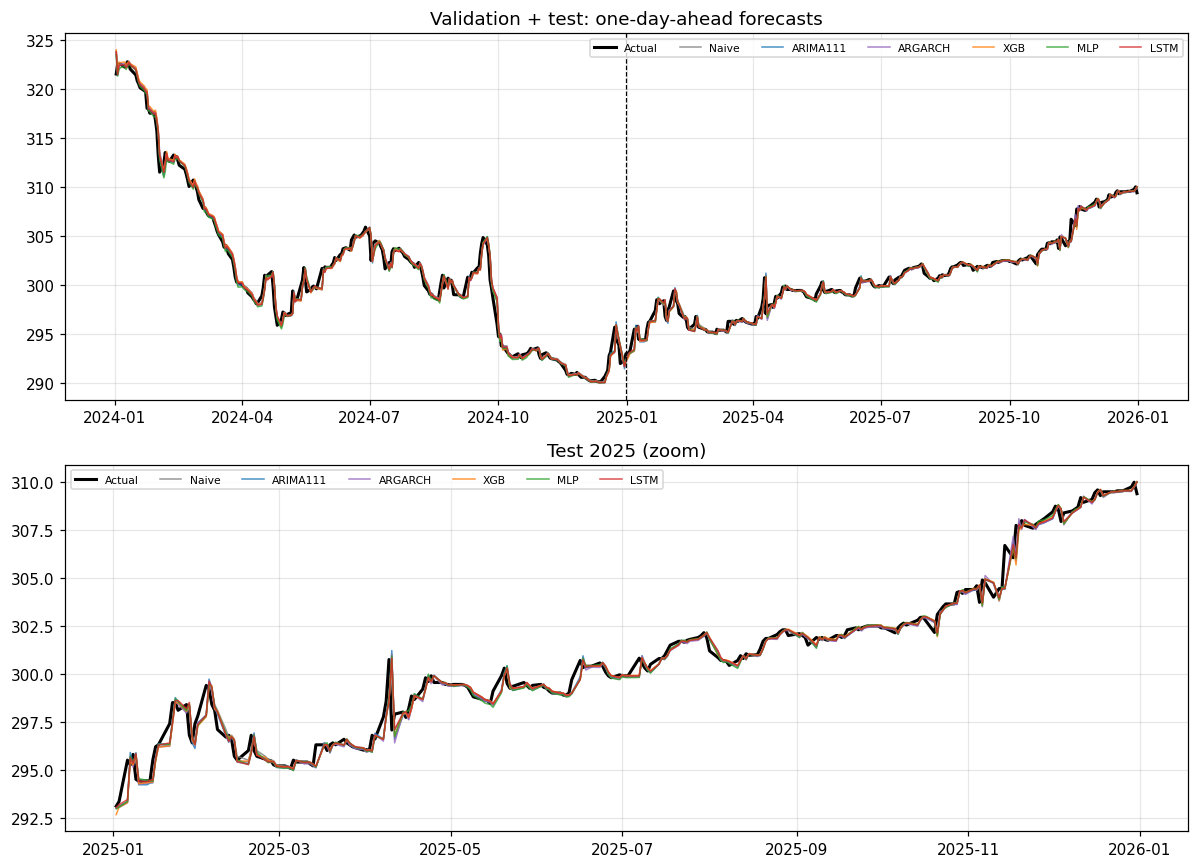

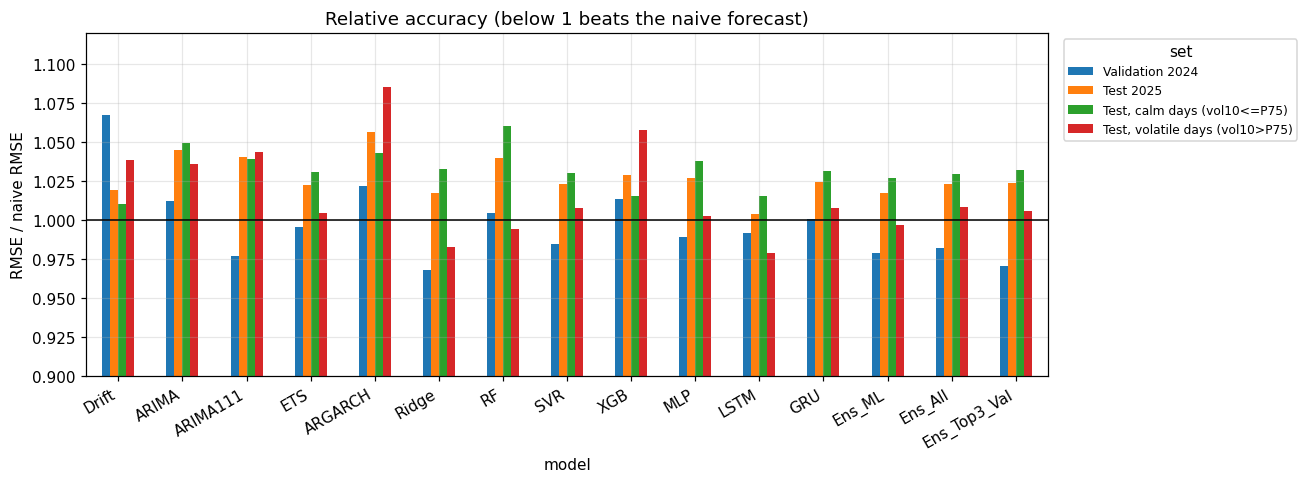

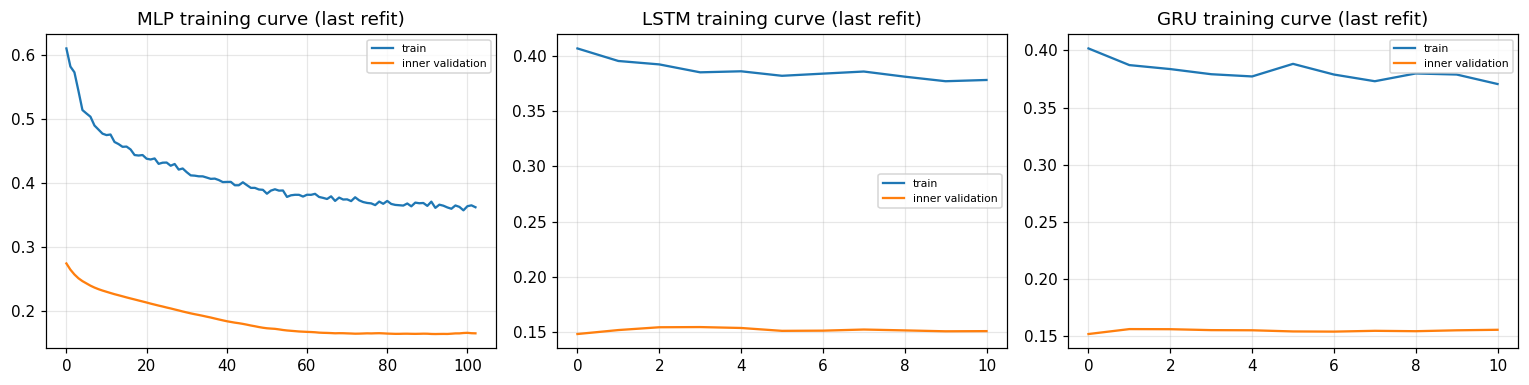

In [ ]:
dv = pred[va_m | te_m]; PL = [("Naive", "tab:gray"), ("ARIMA111", "tab:blue"), ("ARGARCH", "tab:purple"), ("XGB", "tab:orange"), ("MLP", "tab:green"), ("LSTM", "tab:red")]
fig, ax = plt.subplots(2, 1, figsize=(11, 8))
for a, dd, t_ in [(ax[0], dv, "Validation + test: one-day-ahead forecasts"), (ax[1], pred[te_m], "Test 2025 (zoom)")]:
    a.plot(dd.index, dd.P_act, "k", lw=2, label="Actual")
    for m, c in PL: a.plot(dd.index, dd.P_prev * np.exp(dd[m] / 100), c=c, lw=1, alpha=.8, label=m)
    a.set_title(t_); a.legend(ncol=7, fontsize=7)
ax[0].axvline(VAL_END, color="k", ls="--", lw=.8); savefig("04_forecasts")
piv = res.pivot(index="set", columns="model", values="RMSE_vs_naive")[MODELS[1:]].loc[list(SETS)]
ax = piv.T.plot.bar(figsize=(12, 4.5)); ax.axhline(1, c="k", lw=1); ax.set_ylim(min(0.9, piv.min().min() - .02), max(1.12, piv.max().max() + .02)); ax.set_ylabel("RMSE / naive RMSE"); ax.set_title("Relative accuracy (below 1 beats the naive forecast)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, title="set"); plt.xticks(rotation=30, ha="right"); savefig("05_relative_rmse")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for j, kind in enumerate(["mlp", "lstm", "gru"]): ax[j].plot(HIST[kind]["loss"], label="train"); ax[j].plot(HIST[kind]["val_loss"], label="inner validation"); ax[j].set_title(f"{kind.upper()} training curve (last refit)"); ax[j].legend(fontsize=7)
savefig("06_nn_training_curves")

In [ ]:
srows = []
for kind, sp in seed_preds.items():
    for k in range(sp.shape[0]):
        srows.append({"model": kind.upper(), "seed": SEED + k, "val_RMSE_vs_naive": rmse_arr(sp[k], va_m) / naive_val, "test_RMSE_vs_naive": rmse_arr(sp[k], te_m) / base["Test 2025"]})
    srows.append({"model": kind.upper(), "seed": "ensemble mean", "val_RMSE_vs_naive": rmse_arr(sp.mean(0), va_m) / naive_val, "test_RMSE_vs_naive": rmse_arr(sp.mean(0), te_m) / base["Test 2025"]})
stab = pd.DataFrame(srows); print(stab.round(3).to_string(index=False)); stab.to_csv(f"{OUT_DIR}/nn_seed_stability.csv", index=False)

model          seed  val_RMSE_vs_naive  test_RMSE_vs_naive
  MLP            42              0.992               1.030
  MLP            43              1.000               1.020
  MLP            44              0.995               1.047
  MLP ensemble mean              0.989               1.027
 LSTM            42              0.990               1.007
 LSTM            43              1.001               1.001
 LSTM            44              0.991               1.009
 LSTM ensemble mean              0.992               1.004
  GRU            42              0.996               1.039
  GRU            43              1.003               1.027
  GRU            44              1.013               1.013
  GRU ensemble mean              1.000               1.024


Permutation importance = increase in test RMSE (LKR) when the feature is shuffled:
  feature  RF_delta_RMSE  MLP_delta_RMSE  MLP_sd_seeds
  r_lag2        0.00659         0.00356       0.00236
  r_lag4        0.00002         0.00132       0.00122
  r_lag5       -0.00122         0.00120       0.00216
  r_lag3       -0.00021        -0.00003       0.00175
    vol5       -0.00038        -0.00011       0.00135
   mom10       -0.00250        -0.00032       0.00069
abs_lag1       -0.00630        -0.00039       0.00251
dev_ma20       -0.00021        -0.00070       0.00305
   vol20        0.00003        -0.00137       0.00123
   vol10        0.00157        -0.00153       0.00117
   mom20       -0.00230        -0.00155       0.00092
dev_ma10       -0.00331        -0.00220       0.00055
    mom5       -0.00335        -0.00288       0.00256
  r_lag1       -0.01039        -0.00291       0.00540


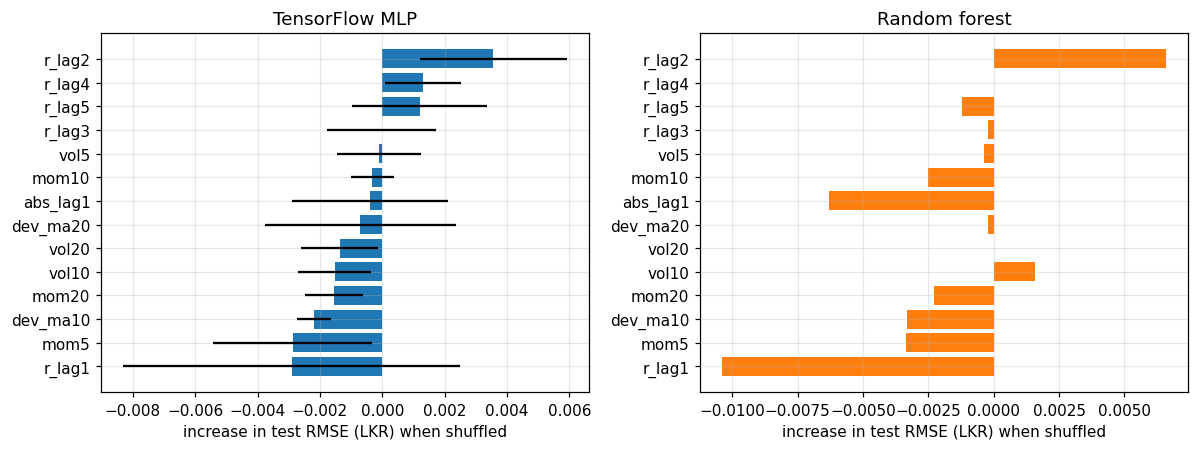


RF impurity importance (top 5):
 r_lag1      0.140
r_lag2      0.128
dev_ma10    0.119
mom5        0.087
r_lag3      0.074

Ridge standardised coefficients (largest):
 r_lag2    0.1281
r_lag1    0.1049
r_lag4   -0.1042
mom5      0.0516
r_lag5   -0.0397


In [ ]:
tr_final = np.arange(0, np.where(te_m)[0][0]); tr_final = tr_final[-WIN:] if WIN else tr_final; te_i = np.where(te_m)[0]
base_rmse = lambda p: float(np.sqrt(((pred.P_act.values[te_i] - pred.P_prev.values[te_i] * np.exp(p / 100)) ** 2).mean()))
rngp = np.random.default_rng(SEED); imp = {c: [] for c in F.columns}
# Random forest
X = FV[tr_final]; mu, sd = X.mean(0), X.std(0) + 1e-9; yt = Y1[tr_final]; sdy = yt.std(); rf = make("RF", **BEST["RF"])(); rf.fit(np.clip((X - mu) / sd, -CLIP, CLIP), np.clip(yt, *np.percentile(yt, [1, 99])) / sdy)
Xte = np.clip((FV[te_i] - mu) / sd, -CLIP, CLIP); b0 = base_rmse(rf.predict(Xte) * sdy); imp_rf = {}
for j, c in enumerate(F.columns):
    dl = []
    for _ in range(20): Xp = Xte.copy(); Xp[:, j] = rngp.permutation(Xp[:, j]); dl.append(base_rmse(rf.predict(Xp) * sdy) - b0)
    imp_rf[c] = np.mean(dl)
# MLP (TensorFlow)
mlp_models = [nn_train("mlp", tr_final, SEED + k, MLP_UNITS, MLP_L2) for k in SEEDS]; imp_nn = {c: [] for c in F.columns}
for m, inp, sdy_, _ in mlp_models:
    Xn = inp(te_i); b1 = base_rmse(m.predict(Xn, verbose=0).ravel() * sdy_)
    for j, c in enumerate(F.columns):
        dl = []
        for _ in range(10): Xp = Xn.copy(); Xp[:, j] = rngp.permutation(Xp[:, j]); dl.append(base_rmse(m.predict(Xp, verbose=0).ravel() * sdy_) - b1)
        imp_nn[c].append(np.mean(dl))
imp_df = pd.DataFrame({"feature": list(F.columns), "RF_delta_RMSE": [imp_rf[c] for c in F.columns], "MLP_delta_RMSE": [np.mean(imp_nn[c]) for c in F.columns], "MLP_sd_seeds": [np.std(imp_nn[c]) for c in F.columns]}).sort_values("MLP_delta_RMSE", ascending=False)
print("Permutation importance = increase in test RMSE (LKR) when the feature is shuffled:\n", imp_df.round(5).to_string(index=False)); imp_df.to_csv(f"{OUT_DIR}/permutation_importance.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2)); ii = imp_df.iloc[::-1]
ax[0].barh(ii.feature, ii.MLP_delta_RMSE, xerr=ii.MLP_sd_seeds); ax[0].set_title("TensorFlow MLP"); ax[1].barh(ii.feature, ii.RF_delta_RMSE, color="tab:orange"); ax[1].set_title("Random forest")
for a in ax: a.set_xlabel("increase in test RMSE (LKR) when shuffled")
savefig("07_permutation_importance")
rc = pd.Series(rf.feature_importances_, index=F.columns).sort_values(ascending=False); print("\nRF impurity importance (top 5):\n", rc.head(5).round(3).to_string())
rd = Ridge(alpha=BEST["Ridge"]["alpha"]).fit(np.clip((X - mu) / sd, -CLIP, CLIP), np.clip(yt, *np.percentile(yt, [1, 99])) / sdy)
print("\nRidge standardised coefficients (largest):\n", pd.Series(rd.coef_, index=F.columns).sort_values(key=abs, ascending=False).head(5).round(4).to_string())

[ 79.2 min] horizon 1 done
[ 83.7 min] horizon 5 done
[ 87.4 min] horizon 10 done
 horizon_days model  n_test   RMSE    MAE  RMSE_vs_naive
            1 Drift     250 0.5412 0.3176         1.0191
            1 Ridge     250 0.5403 0.3160         1.0174
            1    RF     250 0.5522 0.3224         1.0397
            1   SVR     250 0.5435 0.3139         1.0234
            1   XGB     250 0.5464 0.3107         1.0289
            1   MLP     250 0.5453 0.3147         1.0268
            1  LSTM     250 0.5332 0.3090         1.0040
            5 Drift     246 1.1951 0.8504         1.1256
            5 Ridge     246 1.1662 0.8170         1.0984
            5    RF     246 1.0874 0.7786         1.0242
            5   SVR     246 1.1105 0.7730         1.0459
            5   XGB     246 1.1433 0.7747         1.0768
            5   MLP     246 1.1758 0.8399         1.1074
            5  LSTM     246 1.0989 0.7523         1.0350
           10 Drift     241 1.7873 1.4081         1.2789
      

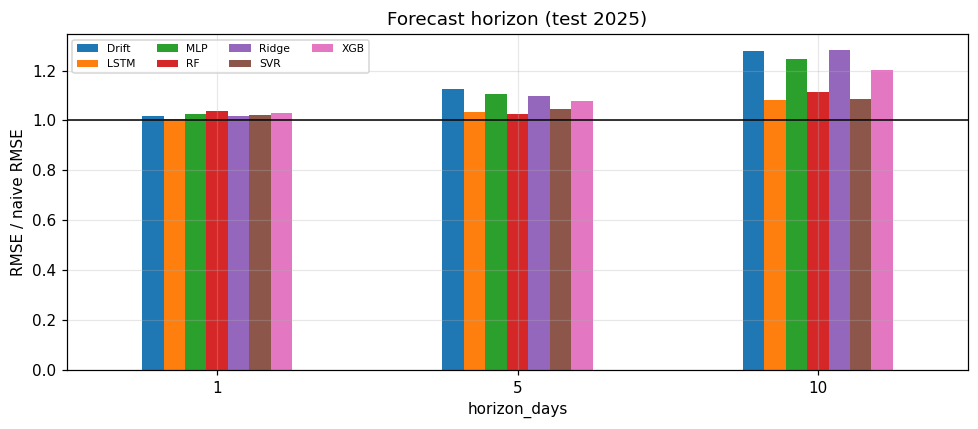

In [ ]:
HOR_NN = ["mlp", "lstm"]; hor_rows = []
for h in (1, 5, 10):
    yh = ((lp.shift(-(h - 1)) - lp.shift(1)) * 100).reindex(idx).values; gap = h - 1
    dfh = pd.DataFrame({"y": yh, "P_prev": pred.P_prev.values}, index=idx); dfh["P_act"] = dfh.P_prev * np.exp(dfh.y / 100)
    dfh["Naive"] = 0.0; dfh["Drift"] = np.nan
    ps = np.where(te_m)[0]; dr = np.full(n, np.nan)
    for s0 in range(0, len(ps), STEP): ch = ps[s0:s0 + STEP]; tr = np.arange(0, ch[0] - gap); tr = tr[-WIN:] if WIN else tr; dr[ch] = Y1[tr].mean() * h
    dfh["Drift"] = dr
    for m in FAST: dfh[m] = pred[m].values if h == 1 else run_model(ml_fn(make(m, **BEST[m]), Yt=yh), WIN, masks=(te_m,), gap=gap)
    for kind in HOR_NN:
        dfh[kind.upper()] = pred[kind.upper()].values if h == 1 else run_model(nn_fn(kind, SEEDS[:1], MLP_UNITS if kind == "mlp" else 16, MLP_L2 if kind == "mlp" else 1e-3, Yt=yh), WIN, masks=(te_m,), gap=gap).mean(0)
    dd = dfh[te_m].dropna(); b = metrics(dd, "Naive")["RMSE"]
    for m in ["Naive", "Drift"] + FAST + [k.upper() for k in HOR_NN]: mm = metrics(dd, m); hor_rows.append([h, m, len(dd), mm["RMSE"], mm["MAE"], mm["RMSE"] / b])
    tick(f"horizon {h} done")
hor = pd.DataFrame(hor_rows, columns=["horizon_days", "model", "n_test", "RMSE", "MAE", "RMSE_vs_naive"]).round(4); print(hor[hor.model != "Naive"].to_string(index=False)); hor.to_csv(f"{OUT_DIR}/horizon.csv", index=False)
ax = hor[hor.model != "Naive"].pivot(index="horizon_days", columns="model", values="RMSE_vs_naive").plot.bar(figsize=(9, 4)); ax.axhline(1, c="k", lw=1)
ax.set_ylabel("RMSE / naive RMSE"); ax.set_title("Forecast horizon (test 2025)"); plt.xticks(rotation=0); ax.legend(ncol=4, fontsize=7); savefig("08_horizon")

                                period    model  RMSE_LKR  RMSE_vs_naive
Whole 2022 shock period (Mar 8-Dec 31)    Naive     4.025          1.000
Whole 2022 shock period (Mar 8-Dec 31)    Drift     4.050          1.006
Whole 2022 shock period (Mar 8-Dec 31) ARIMA111     6.731          1.672
Whole 2022 shock period (Mar 8-Dec 31)      ETS     4.064          1.010
Whole 2022 shock period (Mar 8-Dec 31)  ARGARCH     4.033          1.002
Whole 2022 shock period (Mar 8-Dec 31)    Ridge     4.306          1.070
Whole 2022 shock period (Mar 8-Dec 31)       RF     3.919          0.974
Whole 2022 shock period (Mar 8-Dec 31)      SVR     3.966          0.985
Whole 2022 shock period (Mar 8-Dec 31)      XGB     4.060          1.009
      Devaluation phase (Mar 8-May 31)    Naive     6.432          1.000
      Devaluation phase (Mar 8-May 31)    Drift     6.365          0.990
      Devaluation phase (Mar 8-May 31) ARIMA111    11.830          1.839
      Devaluation phase (Mar 8-May 31)      ETS    

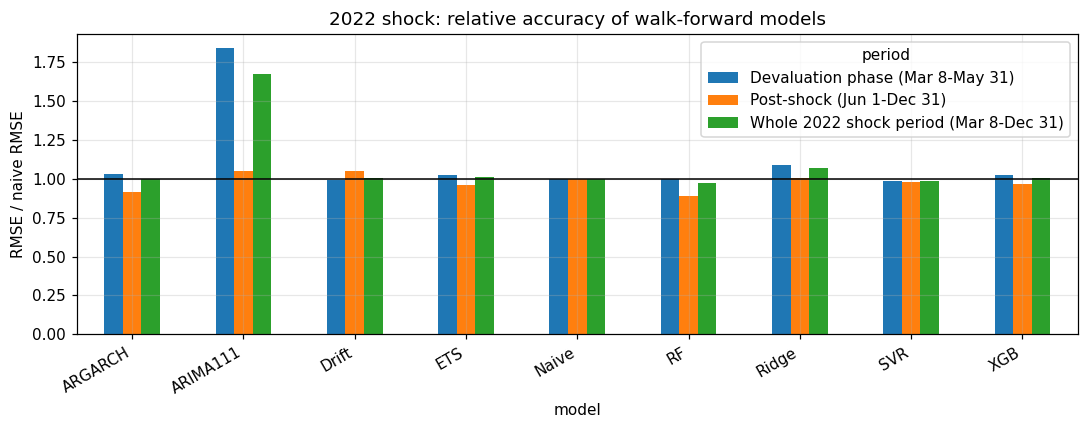


Three largest daily moves in the stress window: [('2022-03-08', np.float64(11.47)), ('2022-03-11', np.float64(7.76)), ('2022-05-05', np.float64(4.92))]


In [ ]:
st_m = np.asarray((idx >= "2022-03-08") & (idx <= "2022-12-31")); shock_m = np.asarray((idx >= "2022-03-08") & (idx <= "2022-05-31")); after_m = np.asarray((idx >= "2022-06-01") & (idx <= "2022-12-31"))
SW = WIN if WIN and WIN <= 250 else 250
stress = {"Naive": np.where(st_m, 0.0, np.nan), "Drift": run_model(drift_fn, SW, masks=(st_m,)), "ARIMA111": run_model(arima_fn((1, 0, 1)), SW, masks=(st_m,)),
          "ETS": run_model(ets_fn, SW, masks=(st_m,)), "ARGARCH": run_model(garch_fn, SW, masks=(st_m,))}
for m in FAST: stress[m] = run_model(ml_fn(make(m, **BEST[m])), SW, masks=(st_m,))
srows = []
for nm_, mk in [("Whole 2022 shock period (Mar 8-Dec 31)", st_m), ("Devaluation phase (Mar 8-May 31)", shock_m), ("Post-shock (Jun 1-Dec 31)", after_m)]:
    bn = rmse_arr(np.zeros(n), mk)
    for m, arr in stress.items(): srows.append({"period": nm_, "model": m, "RMSE_LKR": rmse_arr(np.nan_to_num(arr), mk), "RMSE_vs_naive": rmse_arr(np.nan_to_num(arr), mk) / bn})
stress_df = pd.DataFrame(srows); print(stress_df.round(3).to_string(index=False)); stress_df.to_csv(f"{OUT_DIR}/stress_test_2022.csv", index=False)
ax = stress_df.pivot(index="model", columns="period", values="RMSE_vs_naive").plot.bar(figsize=(10, 4)); ax.axhline(1, c="k", lw=1); ax.set_ylabel("RMSE / naive RMSE"); ax.set_title("2022 shock: relative accuracy of walk-forward models"); plt.xticks(rotation=30, ha="right"); savefig("09_stress_test_2022")
d22 = np.where(st_m)[0]; big = np.argsort(-np.abs(Y1[d22]))[:3]; print("\nThree largest daily moves in the stress window:", [(str(idx[d22[i]].date()), round(Y1[d22[i]], 2)) for i in big])

level                         tail                 method  breaches  expected  Kupiec_p
  95%     rupee weakens (importer)             AR-GARCH-t        18      12.5     0.133
  95%     rupee weakens (importer) Historical sim. (250d)        10      12.5     0.453
  95% rupee strengthens (exporter)             AR-GARCH-t         7      12.5     0.083
  95% rupee strengthens (exporter) Historical sim. (250d)         5      12.5     0.014
  99%     rupee weakens (importer)             AR-GARCH-t         4       2.5     0.380
  99%     rupee weakens (importer) Historical sim. (250d)         3       2.5     0.758
  99% rupee strengthens (exporter)             AR-GARCH-t         1       2.5     0.278
  99% rupee strengthens (exporter) Historical sim. (250d)         1       2.5     0.278

Correlation of |next return| with: GARCH sigma = 0.327 | rolling 10-day std = 0.282 | rolling 20-day std = 0.227


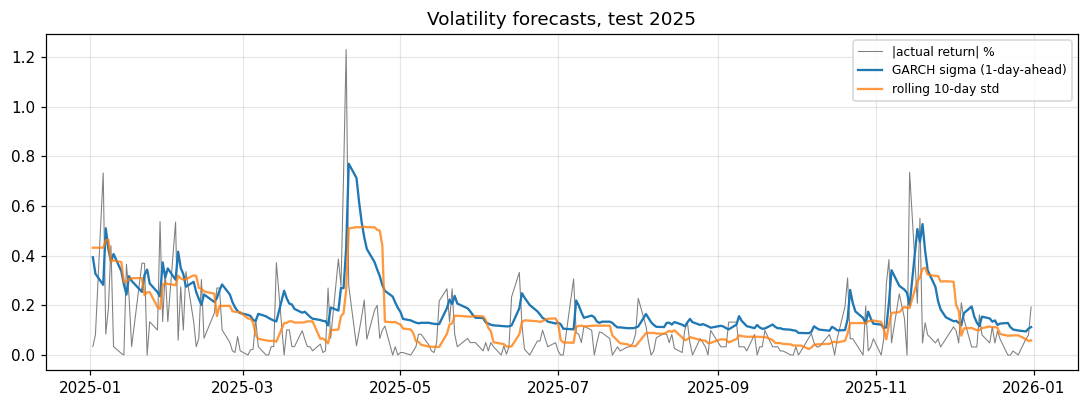

In [ ]:
def kupiec(x, N, p):
    if x == 0: lr = -2 * N * np.log(1 - p)
    else: ph = x / N; lr = -2 * ((N - x) * np.log(1 - p) + x * np.log(p)) + 2 * ((N - x) * np.log(1 - ph) + x * np.log(ph))
    return lr, 1 - stats.chi2.cdf(lr, 1)
rows = []; te_i = np.where(te_m)[0]; ytest = Y1[te_i]
for lev in (.95, .99):
    qz = stats.t.ppf(lev, G_NU[te_i]) * np.sqrt((G_NU[te_i] - 2) / G_NU[te_i])
    hs_up = np.array([np.percentile(Y1[max(0, i - 250):i], lev * 100) for i in te_i]); hs_dn = np.array([np.percentile(Y1[max(0, i - 250):i], (1 - lev) * 100) for i in te_i])
    for tail, g_var, h_var, br in [("rupee weakens (importer)", G_MU[te_i] + G_SIG[te_i] * qz, hs_up, lambda v: ytest > v), ("rupee strengthens (exporter)", G_MU[te_i] - G_SIG[te_i] * qz, hs_dn, lambda v: ytest < v)]:
        for meth, v in [("AR-GARCH-t", g_var), ("Historical sim. (250d)", h_var)]:
            x = int(br(v).sum()); lr, p_ = kupiec(x, len(te_i), 1 - lev); rows.append({"level": f"{lev:.0%}", "tail": tail, "method": meth, "breaches": x, "expected": round((1 - lev) * len(te_i), 1), "Kupiec_p": round(p_, 3)})
var_df = pd.DataFrame(rows); print(var_df.to_string(index=False)); var_df.to_csv(f"{OUT_DIR}/var_backtest.csv", index=False)
rv_ = np.abs(Y1[te_i]); print("\nCorrelation of |next return| with: GARCH sigma =", round(np.corrcoef(G_SIG[te_i], rv_)[0, 1], 3), "| rolling 10-day std =", round(np.corrcoef(vol10.values[te_i], rv_)[0, 1], 3), "| rolling 20-day std =", round(np.corrcoef(F["vol20"].values[te_i], rv_)[0, 1], 3))
fig, ax = plt.subplots(figsize=(10, 3.8)); ax.plot(idx[te_i], rv_, lw=.7, label="|actual return| %", c="gray"); ax.plot(idx[te_i], G_SIG[te_i], label="GARCH sigma (1-day-ahead)"); ax.plot(idx[te_i], vol10.values[te_i], label="rolling 10-day std", alpha=.8)
ax.set_title("Volatility forecasts, test 2025"); ax.legend(fontsize=8); savefig("10_volatility_forecast")

In [ ]:
rows = []
for W in WINDOW_CANDIDATES + [120]:
    for m in FAST + ["ARIMA111"]:
        fn = ml_fn(make(m, **BEST[m])) if m in FAST else arima_fn((1, 0, 1)); arr = run_model(fn, W)
        rows.append({"window": "expanding" if W is None else W, "model": m, "val_RMSE_vs_naive": rmse_arr(arr, va_m) / naive_val, "test_RMSE_vs_naive": rmse_arr(arr, te_m) / base["Test 2025"]})
wt = pd.DataFrame(rows); print(wt.round(3).to_string(index=False)); wt.to_csv(f"{OUT_DIR}/window_sensitivity.csv", index=False)

   window    model  val_RMSE_vs_naive  test_RMSE_vs_naive
      250    Ridge              0.989               1.005
      250       RF              0.999               0.998
      250      SVR              0.986               1.012
      250      XGB              0.991               0.980
      250 ARIMA111              0.974               1.021
      500    Ridge              0.968               1.017
      500       RF              1.004               1.040
      500      SVR              0.985               1.023
      500      XGB              1.014               1.029
      500 ARIMA111              0.977               1.041
expanding    Ridge              0.995               1.037
expanding       RF              1.017               1.028
expanding      SVR              1.005               1.001
expanding      XGB              1.038               0.997
expanding ARIMA111              0.990               1.014
      120    Ridge              1.015               1.024
      120     

In [ ]:
T = res[res.set == "Test 2025"].set_index("model"); V = res[res.set == "Validation 2024"].set_index("model")
summary = pd.DataFrame({"family": T.family, "val_RMSE_vs_naive": V.RMSE_vs_naive, "test_RMSE": T.RMSE, "test_MAE": T.MAE, "test_MAPE_%": T["MAPE_pct"], "test_DirAcc_%": T.DirAcc_pct, "test_RMSE_vs_naive": T.RMSE_vs_naive}).round(4)
summary["DM_p_vs_naive"] = dm[dm.comparison == "vs Naive"].set_index("model").p_value; print(summary.sort_values("test_RMSE").to_string()); summary.sort_values("test_RMSE").to_csv(f"{OUT_DIR}/summary_test.csv")
ac = yr["acf_lag1"].round(3).to_dict(); print("\nLag-1 autocorrelation by year:", ac)
print("Best traditional on test:", bt_, f"({T.loc[bt_,'RMSE_vs_naive']:.3f} x naive) | best ML on test:", bm_, f"({T.loc[bm_,'RMSE_vs_naive']:.3f} x naive)")
print("\nAll outputs saved in:", os.path.abspath(OUT_DIR), f"| total run time {(time.time()-T0)/60:.1f} min")

                        family  val_RMSE_vs_naive  test_RMSE  test_MAE  test_MAPE_%  test_DirAcc_%  test_RMSE_vs_naive  DM_p_vs_naive
model                                                                                                                                
Naive                 Baseline             1.0000     0.5311    0.3096       0.1031            NaN              1.0000            NaN
LSTM          Machine learning             0.9916     0.5332    0.3090       0.1029        54.7511              1.0040         0.5797
Ridge         Machine learning             0.9680     0.5403    0.3160       0.1053        52.4887              1.0174         0.3160
Ens_ML                Ensemble             0.9789     0.5404    0.3098       0.1032        58.8235              1.0175         0.1408
Drift                 Baseline             1.0672     0.5412    0.3176       0.1057        45.7014              1.0191         0.0531
ETS                Traditional             0.9956     0.5431  

In [ ]:
try:
    import shutil; shutil.make_archive("results_2021_2025", "zip", OUT_DIR)
    from google.colab import files; files.download("results_2021_2025.zip")
except Exception as e: print("zip / download skipped:", type(e).__name__)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>